In [177]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, RepeatedKFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

try:
    from xgboost import XGBRegressor
    ADA_XGB = True
except ImportError:
    ADA_XGB = False
    print("xgboost belum terpasang, XGBoost dilewati")


In [178]:
df = pd.read_csv("D:/Porto Magang/Used-car-price-prediction/data/used_car.csv")
print(df.head(5))
print(df.tail(5))

                car name     brand  year  mileage (km)           location  \
0             AYLA X 1.2  Daihatsu  2018        10.508      Jakarta Utara   
1  AGYA TRD SPORTIVO 1.0    Toyota  2015       112.888              Bogor   
2            X-TRAIL 2.5    Nissan  2015       118.429           Surabaya   
3        YARIS S TRD 1.5    Toyota  2020        15.945  Tangerang Selatan   
4             AGYA G 1.2    Toyota  2019        30.404      Jakarta Barat   

  transmission  plate type  rear camera  sun roof  auto retract mirror  \
0       Manual  even plate            0         0                    0   
1       Manual  even plate            0         0                    0   
2    Automatic   odd plate            0         0                    0   
3    Automatic   odd plate            0         0                    0   
4       Manual   odd plate            0         0                    0   

   electric parking brake  map navigator  vehicle stability control  \
0                    

In [179]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 609 entries, 0 to 608
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   car name                   609 non-null    str    
 1   brand                      609 non-null    str    
 2   year                       609 non-null    int64  
 3   mileage (km)               609 non-null    float64
 4   location                   609 non-null    str    
 5   transmission               609 non-null    str    
 6   plate type                 609 non-null    str    
 7   rear camera                609 non-null    int64  
 8   sun roof                   609 non-null    int64  
 9   auto retract mirror        609 non-null    int64  
 10  electric parking brake     609 non-null    int64  
 11  map navigator              609 non-null    int64  
 12  vehicle stability control  609 non-null    int64  
 13  keyless push start         609 non-null    int64  
 14  sport

,year,mileage (km),rear camera,sun roof,auto retract mirror,electric parking brake,map navigator,vehicle stability control,keyless push start,sports mode,360 camera view,power sliding door,auto cruise control,price (Rp),instalment (Rp|Monthly)
count,609.000000,609.00000,609.000000,609.000000,609.000000,609.000000,609.000000,609.000000,609.00000,609.000000,609.00000,609.000000,609.000000,6.090000e+02,6.090000e+02
mean,2018.049261,61.68579,0.142857,0.029557,0.469622,0.031199,0.009852,0.103448,0.08867,0.139573,0.01642,0.014778,0.026273,1.829778e+08,3.728292e+06
std,2.029601,32.14993,0.350215,0.169500,0.499487,0.173997,0.098849,0.304794,0.28450,0.346828,0.12719,0.120764,0.160076,6.688260e+07,1.362950e+06
min,2010.000000,1.06500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,7.700000e+07,1.570000e+06
25%,2017.000000,39.14500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,1.320000e+08,2.690000e+06
50%,2018.000000,58.36500,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,1.770000e+08,3.610000e+06
75%,2019.000000,81.72600,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,0.000000,2.120000e+08,4.320000e+06
max,2023.000000,245.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.00000,1.000000,1.000000,5.420000e+08,1.104000e+07


In [180]:
print("Ukuran Data",df.shape)
print()
print("Total missing value",df.isna().sum())
print()
print("Total duplicated value",df.duplicated().sum())

Ukuran Data (609, 20)

Total missing value car name                     0
brand                        0
year                         0
mileage (km)                 0
location                     0
transmission                 0
plate type                   0
rear camera                  0
sun roof                     0
auto retract mirror          0
electric parking brake       0
map navigator                0
vehicle stability control    0
keyless push start           0
sports mode                  0
360 camera view              0
power sliding door           0
auto cruise control          0
price (Rp)                   0
instalment (Rp|Monthly)      0
dtype: int64

Total duplicated value 0


### Cleaning

In [181]:
df.columns = (
    df.columns.str.strip().str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_")
)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 609 entries, 0 to 608
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   car_name                   609 non-null    str    
 1   brand                      609 non-null    str    
 2   year                       609 non-null    int64  
 3   mileage_km                 609 non-null    float64
 4   location                   609 non-null    str    
 5   transmission               609 non-null    str    
 6   plate_type                 609 non-null    str    
 7   rear_camera                609 non-null    int64  
 8   sun_roof                   609 non-null    int64  
 9   auto_retract_mirror        609 non-null    int64  
 10  electric_parking_brake     609 non-null    int64  
 11  map_navigator              609 non-null    int64  
 12  vehicle_stability_control  609 non-null    int64  
 13  keyless_push_start         609 non-null    int64  
 14  sport

In [182]:
col = df["mileage_km"]
if col.dtype == object:
    df["mileage_km"] = col.str.replace(".", "", regex=False).astype(int)
elif col.max() < 1000:
    df["mileage_km"] = (col * 1000).round().astype(int)
print(df["mileage_km"].describe())

rasio = df["instalment_rp_monthly"] / df["price_rp"]
print(rasio.describe())
df = df.drop(columns=["instalment_rp_monthly"])

count       609.000000
mean      61685.789819
std       32149.930117
min        1065.000000
25%       39145.000000
50%       58365.000000
75%       81726.000000
max      245000.000000
Name: mileage_km, dtype: float64
count    609.000000
mean       0.020375
std        0.000018
min        0.020323
25%        0.020363
50%        0.020377
75%        0.020388
max        0.020421
dtype: float64


### Feature Engineering

## Fitur baru dari kolom yang ada:
- **feature_count**: jumlah fitur tambahan (sunroof, kamera, cruise control, dll) yang dimiliki mobil.
- **engine_l**: kapasitas mesin (liter), dibaca dari nama mobil.
- **age**: umur mobil terhadap tahun terbaru di data (2023).
- **km_per_year**: seberapa intens mobil dipakai per tahun.
- **model** dan **model_group**: nama model (merek + kata pertama nama mobil). Model yang datanya kurang dari 5 digabung per merek jadi `LAINNYA` supaya model tidak menghafal.

In [183]:
fitur = ["rear_camera", "sun_roof", "auto_retract_mirror", "electric_parking_brake",
         "map_navigator", "vehicle_stability_control", "keyless_push_start",
         "sports_mode", "360_camera_view", "power_sliding_door", "auto_cruise_control"]

df["feature_count"] = df[fitur].sum(axis=1)
df["engine_l"] = df["car_name"].str.extract(r"(\d\.\d)")[0].astype(float)
print("mesin kosong:", df["engine_l"].isna().sum())

# tahun acuan = tahun terbaru di data
REF_YEAR = df["year"].max()
df["age"] = REF_YEAR - df["year"]
df["km_per_year"] = df["mileage_km"] / (df["age"] + 1)

# model = brand + kata pertama nama mobil (jadi "Mazda 2", bukan "2")
df["model"] = df["brand"] + " " + df["car_name"].str.split().str[0]

# model yang jarang (<5 data) digabung per brand
jumlah = df["model"].value_counts()
df["model_group"] = df["model"].where(df["model"].map(jumlah) >= 5, df["brand"] + " LAINNYA")

print("model unik:", df["model"].nunique(), "-> setelah digabung:", df["model_group"].nunique())
print(df["brand"].value_counts())
print(df["model_group"].value_counts().head(15))

mesin kosong: 0
model unik: 59 -> setelah digabung: 48
brand
Toyota        171
Honda         145
Daihatsu       82
Mitsubishi     63
Suzuki         62
Nissan         33
Wuling         24
Mazda          19
Datsun          4
Hyundai         3
Chevrolet       1
Ford            1
BMW             1
Name: count, dtype: int64
model_group
Honda BRIO            69
Mitsubishi XPANDER    52
Daihatsu AYLA         36
Toyota KIJANG         34
Toyota AGYA           32
Honda HR-V            29
Toyota AVANZA         25
Toyota RUSH           24
Toyota CALYA          22
Honda MOBILIO         21
Suzuki ERTIGA         21
Daihatsu TERIOS       16
Suzuki IGNIS          14
Wuling ALMAZ          13
Toyota SIENTA         11
Name: count, dtype: int64


### EDA

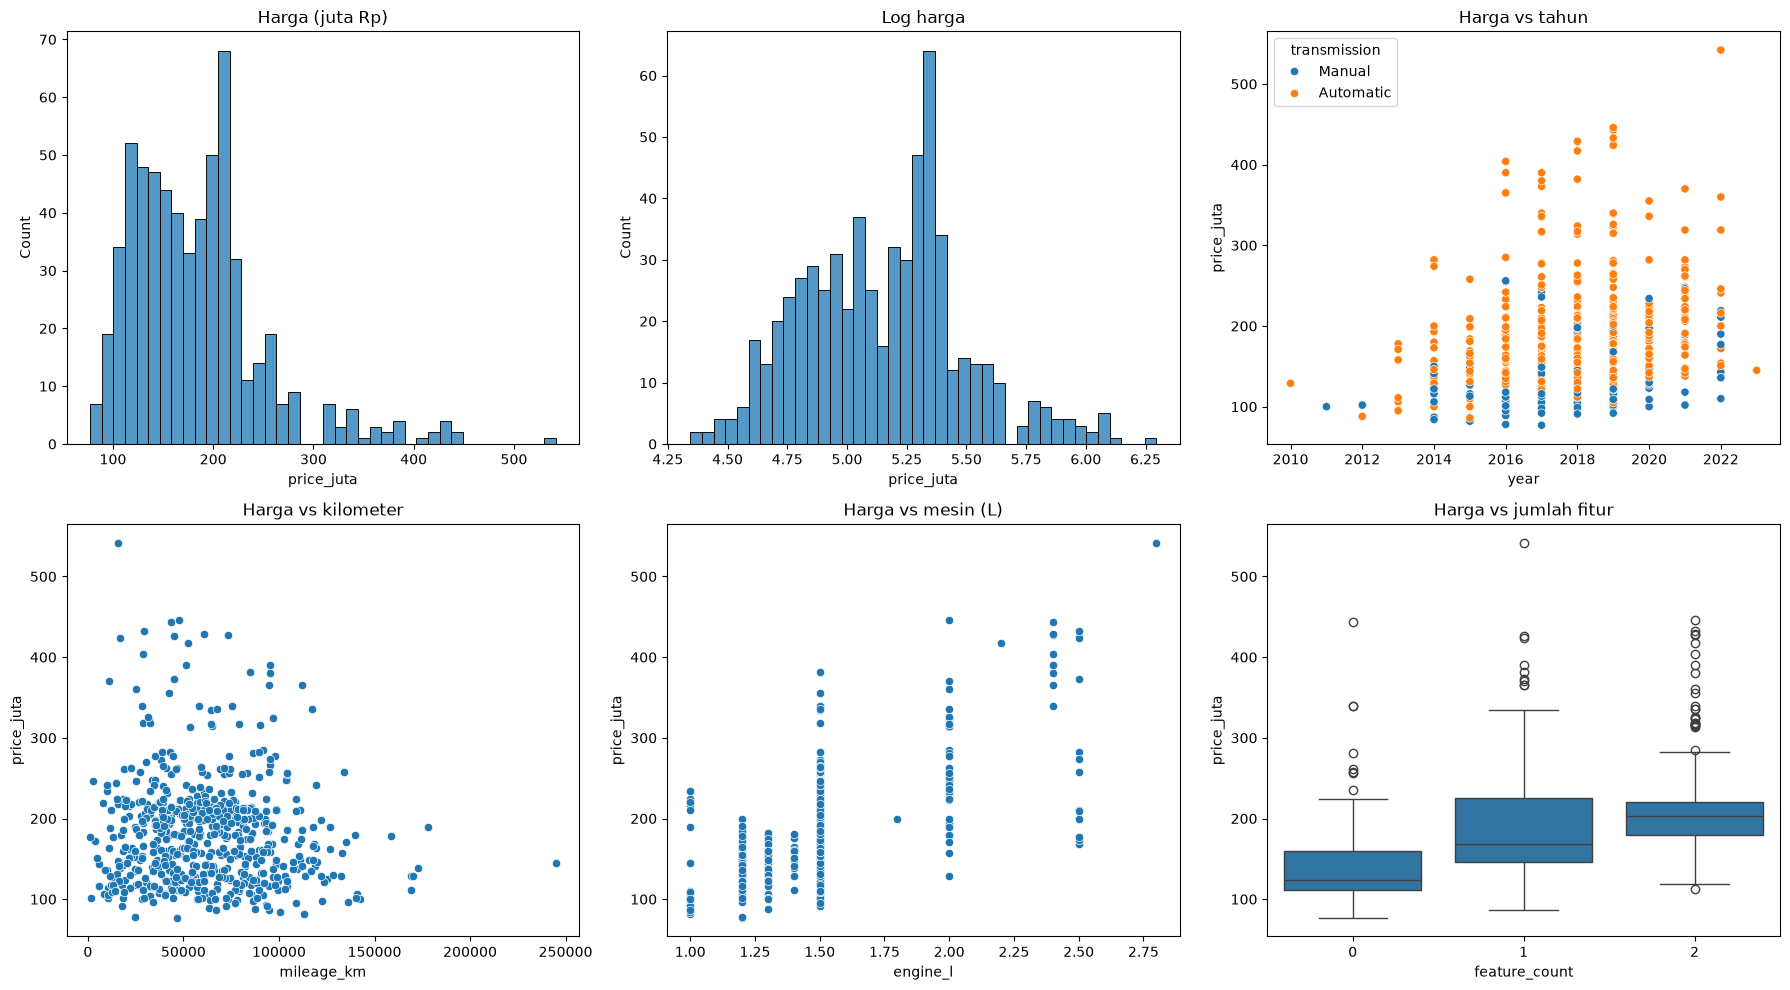

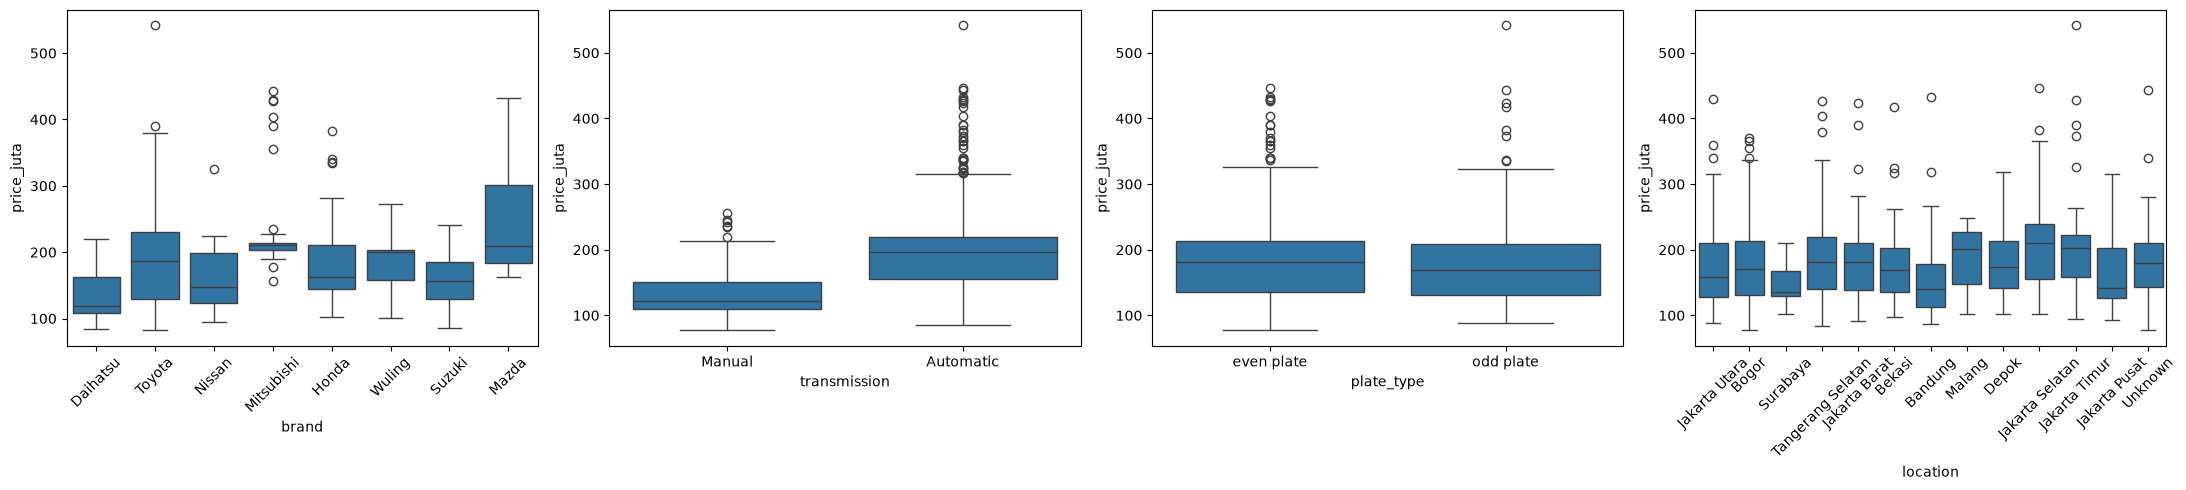

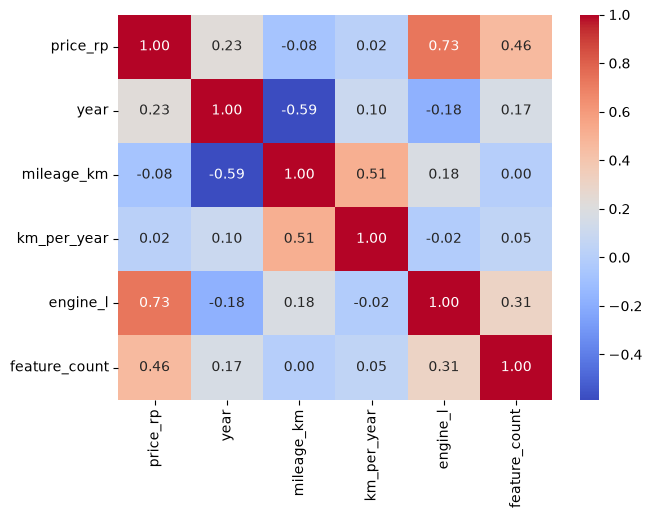

In [184]:
eda = df.assign(price_juta=df["price_rp"] / 1e6)
top_brand = df["brand"].value_counts().head(8).index

fig, ax = plt.subplots(2, 3, figsize=(18, 10))
sns.histplot(eda["price_juta"], bins=40, ax=ax[0, 0]).set_title("Harga (juta Rp)")
sns.histplot(np.log(eda["price_juta"]), bins=40, ax=ax[0, 1]).set_title("Log harga")
sns.scatterplot(data=eda, x="year", y="price_juta", hue="transmission", ax=ax[0, 2]).set_title("Harga vs tahun")
sns.scatterplot(data=eda, x="mileage_km", y="price_juta", ax=ax[1, 0]).set_title("Harga vs kilometer")
sns.scatterplot(data=eda, x="engine_l", y="price_juta", ax=ax[1, 1]).set_title("Harga vs mesin (L)")
sns.boxplot(data=eda, x="feature_count", y="price_juta", ax=ax[1, 2]).set_title("Harga vs jumlah fitur")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 4, figsize=(22, 5))
sns.boxplot(data=eda[eda["brand"].isin(top_brand)], x="brand", y="price_juta", ax=ax[0]).tick_params(axis="x", rotation=45)
sns.boxplot(data=eda, x="transmission", y="price_juta", ax=ax[1])
sns.boxplot(data=eda, x="plate_type", y="price_juta", ax=ax[2])
sns.boxplot(data=eda, x="location", y="price_juta", ax=ax[3]).tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

num = ["price_rp", "year", "mileage_km", "km_per_year", "engine_l", "feature_count"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

In [185]:
kolom = ["car_name", "year", "mileage_km", "engine_l", "price_rp"]
print(df.nlargest(3, "price_rp")[kolom].to_string())
print(df.nlargest(3, "mileage_km")[kolom].to_string())

                                car_name  year  mileage_km  engine_l   price_rp
318            FORTUNER VRZ GR SPORT 2.8  2022       15713       2.8  542000000
575                      3 20I (CKD) 2.0  2019       47554       2.0  446000000
406  PAJERO SPORT DAKAR ULTIMATE 4X2 2.4  2019       43295       2.4  443000000
             car_name  year  mileage_km  engine_l   price_rp
324      S-PRESSO 1.0  2023      245000       1.0  145000000
22      ERTIGA GL 1.5  2022      178000       1.5  190000000
226  AVANZA VELOZ 1.3  2016      172865       1.3  139000000


### Perbandingan Model

In [186]:
num_cols = ["age", "mileage_km", "km_per_year", "engine_l", "feature_count"]
cat_cols = ["brand", "model_group", "location", "transmission"]

X = df[num_cols + cat_cols]
y = df["price_rp"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

def bungkus(model):
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", prep), ("model", model)]),
        func=np.log, inverse_func=np.exp,
    )

kandidat = {
    "Tebak median": DummyRegressor(strategy="median"),
    "Ridge": bungkus(Ridge(alpha=1.0)),
    "RandomForest": bungkus(RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                                  random_state=42, n_jobs=-1)),
}
try:
    from xgboost import XGBRegressor
    kandidat["XGBoost"] = bungkus(XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                                               subsample=0.8, colsample_bytree=0.8, random_state=42))
except ImportError:
    print("xgboost belum terpasang, dilewati")

cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=42)
skor = {"mae": "neg_mean_absolute_error",
        "mape": "neg_mean_absolute_percentage_error",
        "r2": "r2"}

baris = []
for nama, model in kandidat.items():
    h = cross_validate(model, X_train, y_train, cv=cv, scoring=skor)
    baris.append({
        "model": nama,
        "MAE (juta Rp)": -h["test_mae"].mean() / 1e6,
        "MAPE (%)": -h["test_mape"].mean() * 100,
        "R2": h["test_r2"].mean(),
    })

print(pd.DataFrame(baris).sort_values("MAE (juta Rp)").round(2).to_string(index=False))

       model  MAE (juta Rp)  MAPE (%)    R2
       Ridge          12.39      6.30  0.86
     XGBoost          13.63      6.87  0.84
RandomForest          16.62      8.78  0.80
Tebak median          49.60     28.42 -0.04


### Uji Outlier baris janggal

##### Apakah baris mobil s-presso (245.000 KM) merusak model?

In [187]:
print(df.loc[df["car_name"].str.contains("s-presso", case=False),
             ["car_name", "year", "mileage_km", "price_rp"]].sort_values("year").to_string())

num = ["age", "mileage_km", "km_per_year", "engine_l", "feature_count"]
cat = ["brand", "model_group", "transmission"]

def bikin_model():
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", prep), ("model", Ridge(alpha=1.0))]),
        func=np.log, inverse_func=np.exp)

ekstrem = df["mileage_km"] > 200_000
normal, outlier = df[~ekstrem], df[ekstrem]
print("baris ekstrem:", len(outlier))

hasil = {"tanpa baris ekstrem": [], "dengan baris ekstrem": []}
for seed in range(5):
    for tr, te in KFold(5, shuffle=True, random_state=seed).split(normal):
        latih, uji = normal.iloc[tr], normal.iloc[te]
        for nama, data in [("tanpa baris ekstrem", latih),
                           ("dengan baris ekstrem", pd.concat([latih, outlier]))]:
            m = bikin_model().fit(data[num + cat], data["price_rp"])
            hasil[nama].append((m.predict(uji[num + cat]) - uji["price_rp"]).abs().mean() / 1e6)

for nama, e in hasil.items():
    print(f"{nama}: MAE {np.mean(e):.2f} juta (± {np.std(e):.2f})")

         car_name  year  mileage_km   price_rp
324  S-PRESSO 1.0  2023      245000  145000000
baris ekstrem: 1
tanpa baris ekstrem: MAE 11.85 juta (± 1.71)
dengan baris ekstrem: MAE 11.64 juta (± 1.66)


**Hasilnya:** MAE dengan baris itu (11,64 juta) dan tanpa baris itu (11,85 juta) selisihnya jauh lebih kecil daripada variasinya (± 1,7). Jadi baris itu **tidak merusak model dan dipertahankan**.

### Fitur yang berguna

In [188]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
y_train = train_df["price_rp"]

semua_num = ["age", "mileage_km", "km_per_year", "engine_l", "feature_count"]
semua_cat = ["brand", "model_group", "location", "transmission"]

set_fitur = {
    "semua fitur":         (semua_num, semua_cat),
    "tanpa location":      (semua_num, ["brand", "model_group", "transmission"]),
    "tanpa model_group":   (semua_num, ["brand", "location", "transmission"]),
    "tanpa km_per_year":   ([c for c in semua_num if c != "km_per_year"], semua_cat),
    "tanpa feature_count": ([c for c in semua_num if c != "feature_count"], semua_cat),
    "tambah plate_type":   (semua_num, semua_cat + ["plate_type"]),
}

def bangun(model, num, cat):
    prep = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", prep), ("model", model)]),
        func=np.log, inverse_func=np.exp,
    )

cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=42)

hasil = []
for nama_set, (num, cat) in set_fitur.items():
    X_tr = train_df[num + cat]
    modelnya = {
        "Ridge": Ridge(alpha=1.0),
        "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                                subsample=0.8, colsample_bytree=0.8, random_state=42),
    }
    for nama_model, model in modelnya.items():
        h = cross_validate(bangun(model, num, cat), X_tr, y_train, cv=cv,
                           scoring="neg_mean_absolute_error")
        mae = -h["test_score"] / 1e6
        hasil.append({"fitur": nama_set, "model": nama_model,
                      "MAE (juta)": mae.mean(), "± std": mae.std()})

print(pd.DataFrame(hasil).round(2).to_string(index=False))

              fitur   model  MAE (juta)  ± std
        semua fitur   Ridge       12.39   1.59
        semua fitur XGBoost       13.63   2.44
     tanpa location   Ridge       12.28   1.66
     tanpa location XGBoost       13.31   2.42
  tanpa model_group   Ridge       20.42   1.81
  tanpa model_group XGBoost       17.59   2.78
  tanpa km_per_year   Ridge       12.34   1.66
  tanpa km_per_year XGBoost       13.17   2.30
tanpa feature_count   Ridge       12.73   1.73
tanpa feature_count XGBoost       13.55   2.22
  tambah plate_type   Ridge       12.44   1.57
  tambah plate_type XGBoost       13.76   2.37


bandingkan setiap baris dengan "semua fitur" (kolom `± std` adalah variasi antar lipatan).
- **`model_group` sangat penting:** tanpa fitur ini error Ridge naik dari 12,4 menjadi 20,4 juta dan XGBoost dari 13,6 menjadi 17,6 juta. Wajar: harga sangat ditentukan oleh modelnya (Brio vs Fortuner).
- **`location`, `km_per_year`, dan `plate_type` tidak menambah akurasi.** Membuang `location` atau `km_per_year` malah sedikit menurunkan error, tapi selisihnya lebih kecil daripada `± std`, jadi itu bukan perbaikan yang nyata, hanya berarti fitur itu tidak diperlukan.
- `feature_count` sedikit berguna untuk Ridge (error naik saat dibuang), dan dipertahankan.

### Tetapkan fitur final
Dari langkah 7, `location` dan `km_per_year` tidak diperlukan. Sebelum membuang keduanya sekaligus, kita pastikan lewat validasi silang di data latih (tanpa menyentuh data uji) bahwa gabungan itu tidak merusak. Prinsipnya: kalau selisihnya lebih kecil daripada variasi, **pilih model yang lebih sederhana**.

In [189]:
num_final = [c for c in semua_num if c != "km_per_year"]
cat_final = [c for c in semua_cat if c != "location"]

kandidat_final = {
    "semua fitur":                  (semua_num, semua_cat),
    "tanpa location":               (semua_num, cat_final),
    "tanpa location & km_per_year": (num_final, cat_final),
}

baris = []
for nama_set, (num, cat) in kandidat_final.items():
    h = cross_validate(bangun(Ridge(alpha=1.0), num, cat), train_df[num + cat], y_train,
                       cv=cv, scoring="neg_mean_absolute_error")
    mae = -h["test_score"] / 1e6
    baris.append({"fitur": nama_set, "jumlah fitur": len(num) + len(cat),
                  "MAE (juta)": mae.mean(), "± std": mae.std()})

print(pd.DataFrame(baris).round(2).to_string(index=False))
print("\nFitur final angka  :", num_final)
print("Fitur final kategori:", cat_final)

                       fitur  jumlah fitur  MAE (juta)  ± std
                 semua fitur             9       12.39   1.59
              tanpa location             8       12.28   1.66
tanpa location & km_per_year             7       12.23   1.74

Fitur final angka  : ['age', 'mileage_km', 'engine_l', 'feature_count']
Fitur final kategori: ['brand', 'model_group', 'transmission']


### Uji akhir pada data

In [190]:
model_final = bangun(Ridge(alpha=1.0), num_final, cat_final)
model_final.fit(train_df[num_final + cat_final], y_train)

y_test = test_df["price_rp"]
pred = model_final.predict(test_df[num_final + cat_final])
tebak = np.full(len(y_test), y_train.median())


def ringkas(asli, tebakan):
    return {"MAE (juta Rp)": mean_absolute_error(asli, tebakan) / 1e6,
            "MAPE (%)": mean_absolute_percentage_error(asli, tebakan) * 100,
            "Median error (%)": np.median(np.abs(tebakan - asli) / asli) * 100,
            "R2": r2_score(asli, tebakan)}


ujian = pd.DataFrame({"Ridge (fitur final)": ringkas(y_test, pred),
                      "Tebak median": ringkas(y_test, tebak)}).T
print("Jumlah data uji:", len(test_df))
print(ujian.round(2).to_string())

Jumlah data uji: 122
                     MAE (juta Rp)  MAPE (%)  Median error (%)    R2
Ridge (fitur final)          12.97      6.01              3.64  0.90
Tebak median                 52.73     27.36             21.64 -0.07


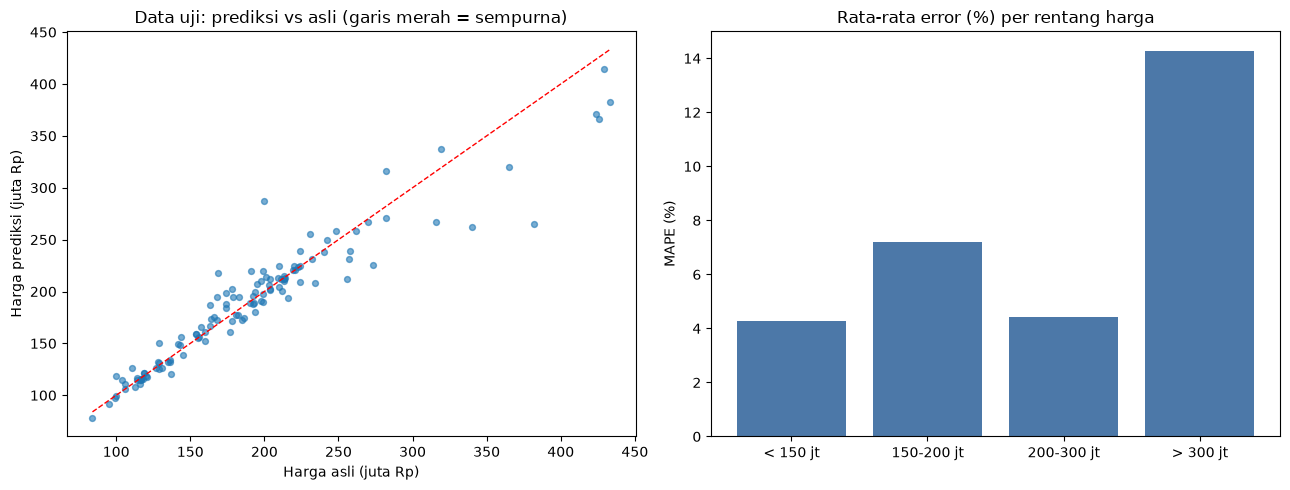

            jumlah  MAPE
pita_harga              
< 150 jt        36   4.3
150-200 jt      40   7.2
200-300 jt      37   4.4
> 300 jt         9  14.3

Error per merek (hanya merek dengan >= 10 data uji):
            jumlah  MAPE
brand                   
Toyota          33   7.0
Honda           29   5.5
Suzuki          14   3.6
Daihatsu        13   3.6
Mitsubishi      11   2.9


In [191]:
err = pd.DataFrame({"brand": test_df["brand"].values,
                    "harga_juta": y_test.values / 1e6,
                    "error_%": np.abs(pred - y_test.values) / y_test.values * 100})
err["pita_harga"] = pd.cut(err["harga_juta"], [0, 150, 200, 300, 1000],
                           labels=["< 150 jt", "150-200 jt", "200-300 jt", "> 300 jt"])
per_pita = err.groupby("pita_harga", observed=True)["error_%"].agg(jumlah="size", MAPE="mean")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test / 1e6, pred / 1e6, s=18, alpha=0.6)
batas = [y_test.min() / 1e6, y_test.max() / 1e6]
ax[0].plot(batas, batas, "r--", lw=1)
ax[0].set_xlabel("Harga asli (juta Rp)")
ax[0].set_ylabel("Harga prediksi (juta Rp)")
ax[0].set_title("Data uji: prediksi vs asli (garis merah = sempurna)")

ax[1].bar(per_pita.index.astype(str), per_pita["MAPE"], color="#4c78a8")
ax[1].set_title("Rata-rata error (%) per rentang harga")
ax[1].set_ylabel("MAPE (%)")
plt.tight_layout()
plt.show()

print(per_pita.round(1).to_string())
per_merek = err.groupby("brand")["error_%"].agg(jumlah="size", MAPE="mean")
print("\nError per merek (hanya merek dengan >= 10 data uji):")
print(per_merek[per_merek["jumlah"] >= 10].sort_values("jumlah", ascending=False).round(1).to_string())

### Fitur yang paling berpengaruh(interpretasi model ridge)

In [192]:
reg = model_final.regressor_
nama_fitur = reg.named_steps["prep"].get_feature_names_out()
koef = pd.Series(reg.named_steps["model"].coef_, index=nama_fitur)

efek_angka = koef[koef.index.str.startswith("num__")]
efek_persen = ((np.exp(efek_angka) - 1) * 100).rename(lambda s: s.replace("num__", ""))
print("Efek fitur angka pada harga (% per kenaikan 1 simpangan baku):")
print(efek_persen.round(1).to_string())

model_koef = koef[koef.index.str.startswith("cat__model_group_")]
model_koef = model_koef.rename(lambda s: s.replace("cat__model_group_", "")).sort_values()
print("\nModel yang lebih MURAH dari mobil sejenis (koefisien log, makin negatif makin murah):")
print(model_koef.head(5).round(2).to_string())
print("\nModel yang lebih MAHAL dari mobil sejenis:")
print(model_koef.tail(5).round(2).to_string())

Efek fitur angka pada harga (% per kenaikan 1 simpangan baku):
age             -10.1
mileage_km       -1.3
engine_l         16.6
feature_count     3.2

Model yang lebih MURAH dari mobil sejenis (koefisien log, makin negatif makin murah):
Suzuki CARRY     -0.37
Wuling CONFERO   -0.26
Toyota AGYA      -0.24
Toyota CALYA     -0.23
Datsun LAINNYA   -0.19

Model yang lebih MAHAL dari mobil sejenis:
Daihatsu ROCKY       0.17
BMW LAINNYA          0.19
Toyota FORTUNER      0.19
Mitsubishi PAJERO    0.24
Honda CR-V           0.28
